In [37]:
import torch
from torch.utils import data
from torch import nn
import matplotlib.pyplot as plt
torch.manual_seed(42)

In [38]:
def data_maker(w,b,num):
    x=torch.randn(num,200)
    y=torch.matmul(x,w)+b
    y+=torch.normal(size=y.size(),mean=0,std=0.01)
    return x,y
true_w=torch.ones((200,1))*0.01
true_b=0.05
#features,labels=data_maker(true_w,true_b,120)
#train_features,train_labels=features[:20],labels[:20]

train_features,train_labels=data_maker(true_w,true_b,20)
test_features,test_labels=data_maker(true_w,true_b,100)
batch_size=5

In [39]:
def data_loader(data_arry,batch_size,shuffle1):
    dataset=data.TensorDataset(*(data_arry))
    return data.DataLoader(dataset,batch_size,shuffle=shuffle1)
train_iter=data_loader((train_features,train_labels),batch_size,shuffle1=True)
test_iter=data_loader((test_features,test_labels),batch_size,shuffle1=False)



In [40]:
def init(m):
    if type(m)==nn.Linear:
        nn.init.normal_(m.weight,mean=0,std=1)
        nn.init.zeros_(m.bias)

In [41]:
def train(lamba):
    net=nn.Sequential(nn.Linear(200,1))
    net.apply(init)
    loss=nn.MSELoss()
    epoch=100
    lr=0.003
    trainer=torch.optim.SGD([{"params":net[0].weight,"weight_decay":lamba},{"params": net[0].bias}],lr=lr)
    train_loss=[]
    test_loss=[]
    for i in range(epoch):
        net.train()
        for x,y in train_iter:
            trainer.zero_grad()
            l=loss(net(x),y)
            l.backward()
            trainer.step()
        net.eval()
        train_loss_sum=0.0
        test_loss_sum=0.0
        l=loss(net(train_features),train_labels)
        train_loss_sum+=l
        l=loss(net(test_features),test_labels)
        test_loss_sum+=l
        train_loss.append(train_loss_sum.item())
        test_loss.append(test_loss_sum.item())

    plt.plot(range(1,epoch+1),train_loss,label='train')
    plt.plot(range(1,epoch+1),test_loss,label='test')
    plt.yscale("log")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.grid()
    plt.show()

            

    

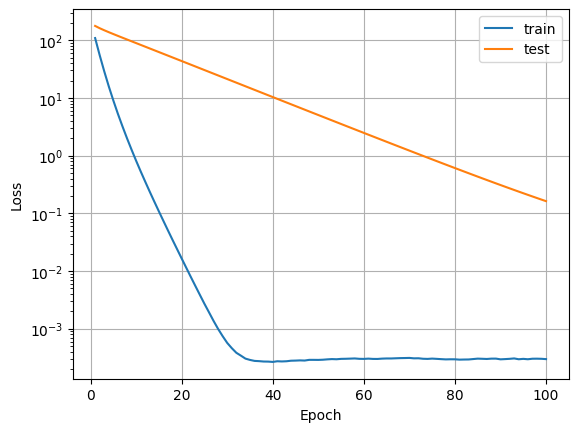

In [42]:
train(3)

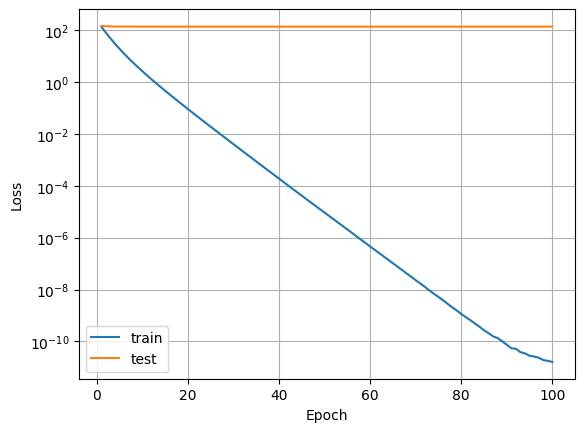

In [43]:
train(0)